# VOA-ukr metadata statistics

Reads `dataset/voa_ukr_meta.json` and plots what is in it. A partial file is fine. Run this notebook locally from the repo, with the kernel working directory at the repo root or in `notebooks/`. Figures are written to `dataset/figures`.

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

def find_meta() -> Path:
    relative = Path("dataset") / "voa_ukr_meta.json"
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        path = candidate / relative
        if path.is_file():
            return path
    raise FileNotFoundError("dataset/voa_ukr_meta.json was not found from the current directory")


meta_path = find_meta()
payload = json.loads(meta_path.read_text(encoding="utf-8"))
rows = payload["files"] if isinstance(payload, dict) else payload
df = pd.DataFrame(rows)
print(meta_path)
print("records", len(df), "updated", payload.get("updated") if isinstance(payload, dict) else None)

figure_dir = meta_path.parent / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)


def save_fig(name: str) -> None:
    plt.tight_layout()
    plt.savefig(figure_dir / name, dpi=120, bbox_inches="tight")
    plt.show()

/home/romardoss/asr/asr_ssl/dataset/voa_ukr_meta.json
records 2613 updated 2026-09-23T21:49:03.149156+00:00


In [4]:
ok = df[df["error"].isna()] if "error" in df.columns else df
hours = ok["duration_seconds"].fillna(0).sum() / 3600 if "duration_seconds" in ok.columns else 0
labelled_rate = ok["is_labelled"].fillna(False).mean() if "is_labelled" in ok.columns else None
n_errors = int(df["error"].notna().sum()) if "error" in df.columns else 0
n_speakers = ok["speaker_id"].nunique(dropna=True) if "speaker_id" in ok.columns else 0

summary = pd.DataFrame(
    {
        "value": [
            len(df),
            len(ok),
            n_errors,
            round(hours, 2),
            None if labelled_rate is None else round(float(labelled_rate), 3),
            n_speakers,
            ok["source"].dropna().unique().tolist() if "source" in ok.columns else None,
            ok["split"].dropna().unique().tolist() if "split" in ok.columns else None,
        ]
    },
    index=[
        "records",
        "without_error",
        "errors",
        "hours",
        "labelled_fraction",
        "speaker_ids",
        "source",
        "split",
    ],
)
summary

,value
records,2613
without_error,2613
errors,0
hours,233.04
labelled_fraction,0.0
speaker_ids,0
source,[robinhad/VOA-ukr]
split,[train]


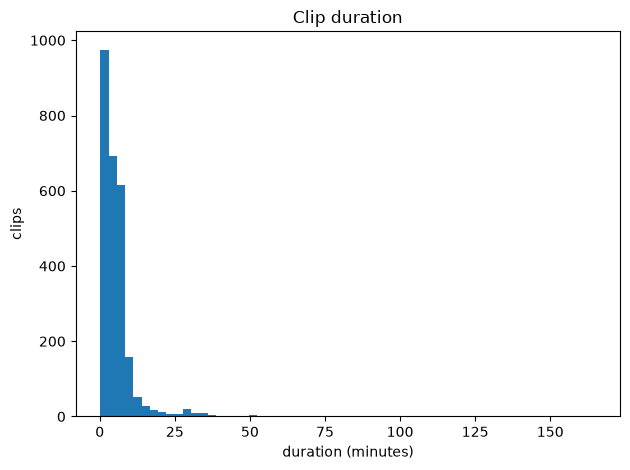

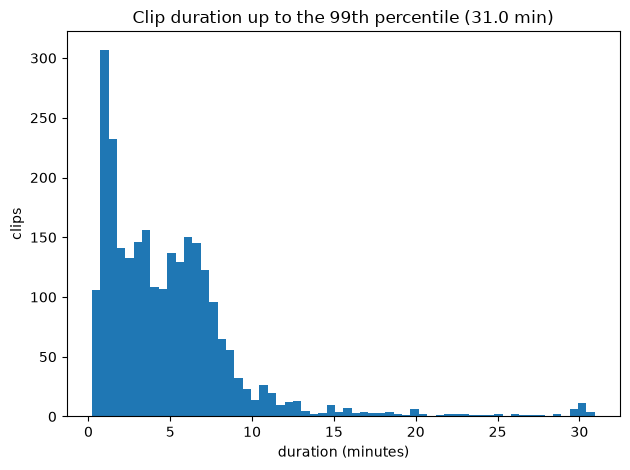

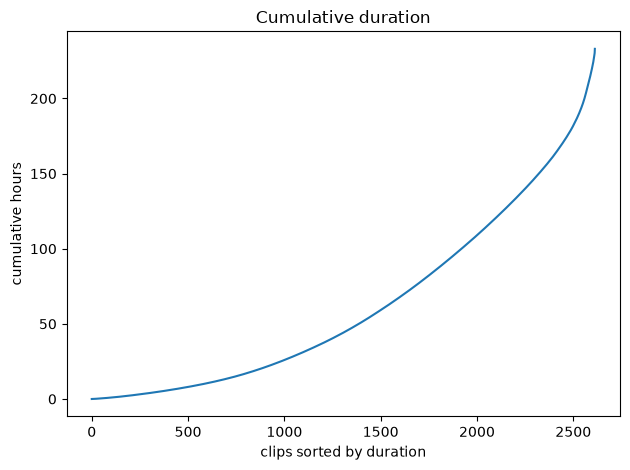

In [5]:
if "duration_seconds" not in ok.columns or ok["duration_seconds"].dropna().empty:
    print("no durations to plot")
else:
    duration_min = ok["duration_seconds"].dropna() / 60
    plt.figure()
    plt.hist(duration_min, bins=60)
    plt.xlabel("duration (minutes)")
    plt.ylabel("clips")
    plt.title("Clip duration")
    save_fig("duration_hist.png")

    cap = duration_min.quantile(0.99)
    plt.figure()
    plt.hist(duration_min[duration_min <= cap], bins=60)
    plt.xlabel("duration (minutes)")
    plt.ylabel("clips")
    plt.title(f"Clip duration up to the 99th percentile ({cap:.1f} min)")
    save_fig("duration_hist_p99.png")

    ordered = ok["duration_seconds"].fillna(0).sort_values()
    plt.figure()
    plt.plot(range(len(ordered)), ordered.cumsum() / 3600)
    plt.xlabel("clips sorted by duration")
    plt.ylabel("cumulative hours")
    plt.title("Cumulative duration")
    save_fig("duration_cumulative.png")

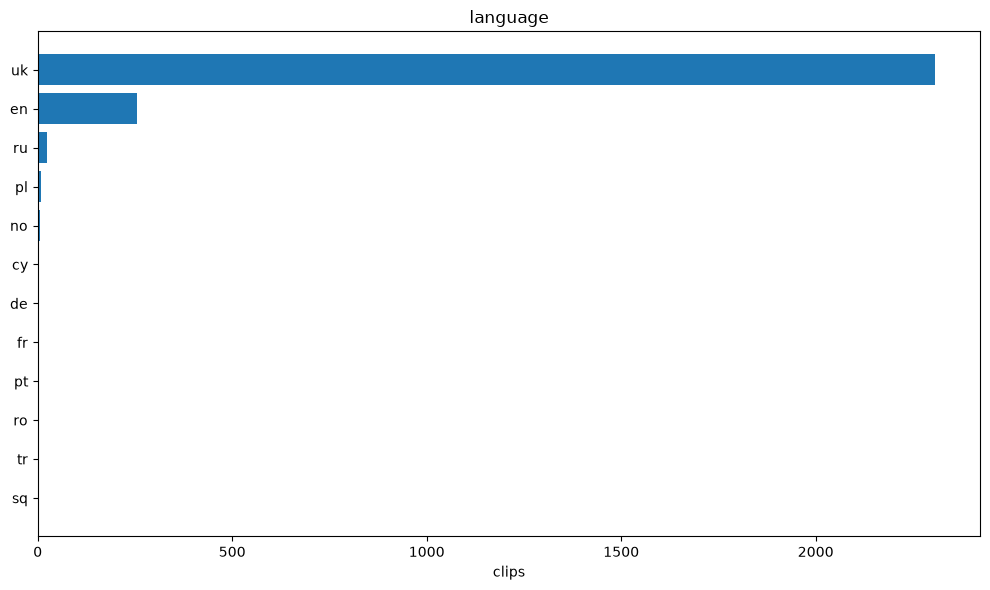

In [6]:
def language_pie(column: str, filename: str) -> None:
    if column not in ok.columns:
        print("missing", column)
        return
    counts = ok[column].fillna("unknown").value_counts()
    plt.figure(figsize=(8, 6))
    wedges, _ = plt.pie(counts.values, startangle=90)
    plt.legend(
        wedges,
        [f"{name} ({count})" for name, count in counts.items()],
        title=column,
        loc="center left",
        bbox_to_anchor=(1, 0.5),
    )
    plt.title(column)
    save_fig(filename)


language_pie("language", "language.png")

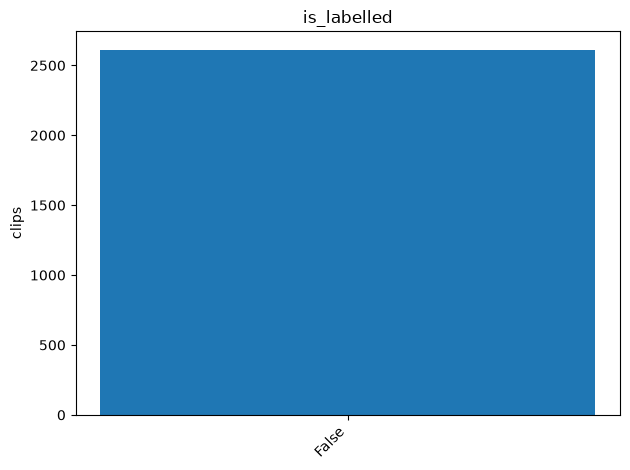

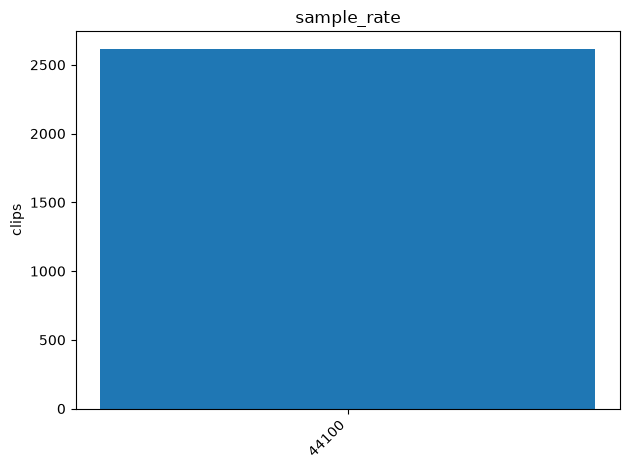

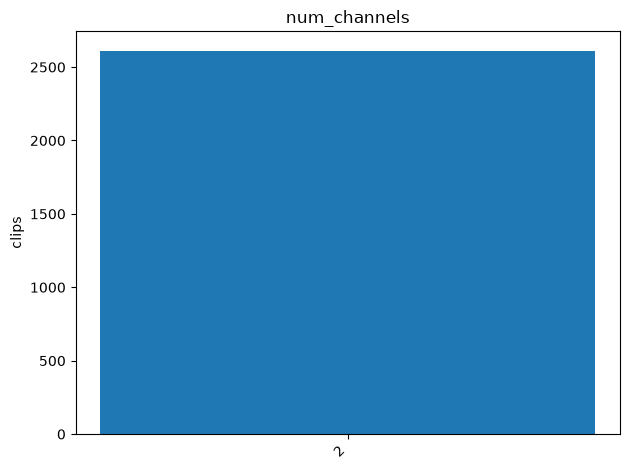

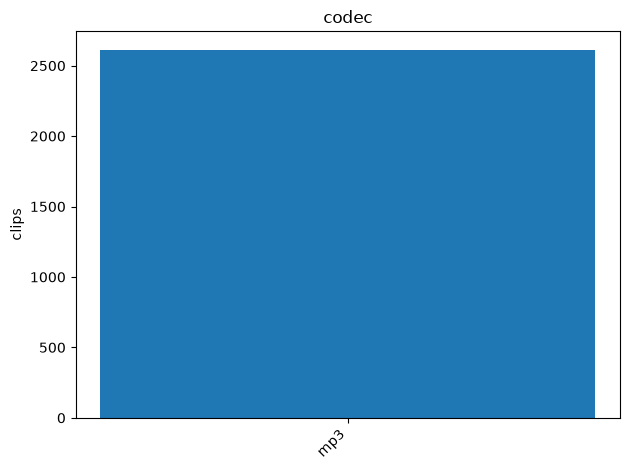

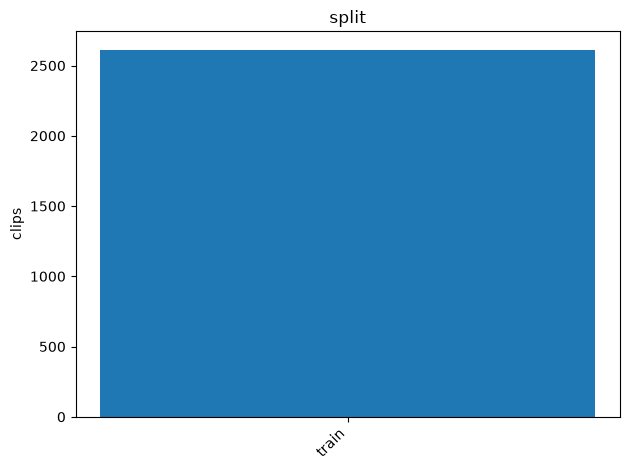

speaker_id is set on 0 of 2613 clips


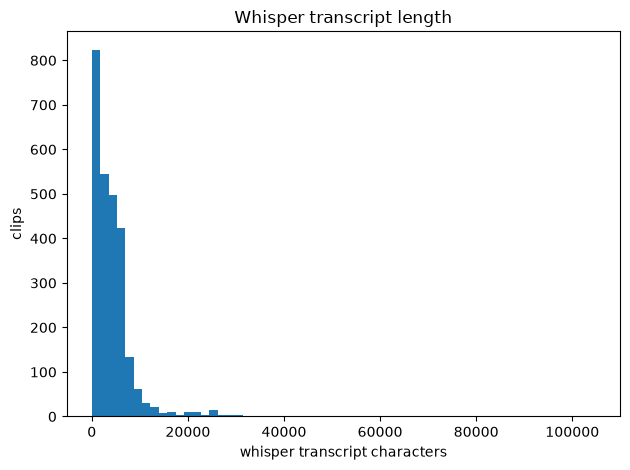

TypeError: boxplot() got an unexpected keyword argument 'labels'

<Figure size 1000x400 with 0 Axes>

In [7]:
def count_bar(column: str, filename: str) -> None:
    if column not in ok.columns:
        print("missing", column)
        return
    counts = ok[column].fillna("missing").astype(str).value_counts()
    plt.figure()
    plt.bar(counts.index.astype(str), counts.values)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("clips")
    plt.title(column)
    save_fig(filename)


count_bar("is_labelled", "is_labelled.png")
count_bar("sample_rate", "sample_rate.png")
count_bar("num_channels", "num_channels.png")
count_bar("codec", "codec.png")
count_bar("split", "split.png")

if "speaker_id" in ok.columns:
    known = int(ok["speaker_id"].notna().sum())
    print(f"speaker_id is set on {known} of {len(ok)} clips")

if "whisper_transcription" in ok.columns:
    lengths = ok["whisper_transcription"].fillna("").str.len()
    plt.figure()
    plt.hist(lengths, bins=60)
    plt.xlabel("whisper transcript characters")
    plt.ylabel("clips")
    plt.title("Whisper transcript length")
    save_fig("whisper_length.png")

if {"language", "duration_seconds"} <= set(ok.columns):
    top = ok["language"].value_counts().head(8).index
    pairs = []
    for language in top:
        series = ok.loc[ok["language"] == language, "duration_seconds"].dropna() / 60
        if len(series):
            pairs.append((language, series))
    if pairs:
        plt.figure(figsize=(10, 4))
        plt.boxplot(
            [series for _, series in pairs],
            tick_labels=[language for language, _ in pairs],
            showfliers=False,
        )
        plt.ylabel("duration (minutes)")
        plt.title("Duration by Whisper language")
        save_fig("duration_by_language.png")

print("figures", figure_dir)